# Morphological measures: describing a body with numbers

`MorphologicalMeasures` takes a built robot (the `CoreModule` that `construct_mjspec_from_graph` or a prebuilt builder returns) and turns its shape into numbers: how branched it is, how many limbs it has, how symmetric it is, how much of its bounding box it fills, and so on. The counts come from the graph the robot was built from; the size and the symmetry come from the robot's geoms at joint angle zero, in metres. Evolution can use these numbers as a fitness or as a way to compare bodies.

In this notebook you build seven bodies, draw each one from above as MuJoCo places it, and read their measures from one table. The pictures and the numbers should agree: a snake is long and thin, a cross is symmetric, and a limb that folds back through a hinge keeps all its modules. No graphics backend is needed.

In [1]:
# Standard library
import math
import random

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from rich.table import Table

In [3]:
# Local libraries
from ariel import console
from ariel.body_phenotypes import (
    MorphologicalMeasures,
    construct_mjspec_from_graph,
)
from ariel.body_phenotypes.robogen_lite import rest_boxes
from ariel.ec.genotypes.tree import TreeGenome, random_tree
from ariel.ec.genotypes.tree.tree_genome import TreeEdge, TreeNode

In [4]:
# Seed
SEED = 42
random.seed(SEED)
MEASURES = (
    "branching",
    "limbs",
    "length_of_limbs",
    "coverage",
    "proportion",
    "symmetry",
    "joints",
    "module_diversity",
)
CORE_SIDE = 0.15  # metres, the measured core
FOLDED_MODULES = 3  # core, hinge, brick

## Seven bodies

A body starts as a `TreeGenome`: nodes with a module type (CORE, BRICK, HINGE) and edges that name the face of the parent the child is attached to. A child's faces are its own: a hinge hung on the core's BACK points backwards, so the brick on its FRONT continues away from the core (the "folded" body). The first six are built by hand so their shape is known; the last is random. Each is built into a robot, and the robot is measured.

In [5]:
def body(
    types: dict[int, str], edges: list[tuple[int, int, str]]
) -> TreeGenome:
    return TreeGenome(
        nodes={i: TreeNode(type=t, rotation="DEG_0") for i, t in types.items()},
        edges=[TreeEdge(parent=p, child=c, face=f) for p, c, f in edges],
    )


bodies = {
    "core only": body({0: "CORE"}, []),
    "snake": body(
        {0: "CORE", 1: "BRICK", 2: "HINGE", 3: "BRICK", 4: "BRICK"},
        [(0, 1, "FRONT"), (1, 2, "FRONT"), (2, 3, "FRONT"), (3, 4, "FRONT")],
    ),
    "cross": body(
        {0: "CORE", 1: "BRICK", 2: "BRICK", 3: "BRICK", 4: "BRICK"},
        [(0, 1, "FRONT"), (0, 2, "BACK"), (0, 3, "RIGHT"), (0, 4, "LEFT")],
    ),
    "walker": body(
        {
            0: "CORE",
            1: "HINGE",
            2: "BRICK",
            3: "BRICK",
            4: "BRICK",
            5: "BRICK",
            6: "BRICK",
        },
        [
            (0, 1, "FRONT"),
            (1, 2, "FRONT"),
            (0, 3, "RIGHT"),
            (3, 4, "FRONT"),
            (0, 5, "LEFT"),
            (5, 6, "FRONT"),
        ],
    ),
    "lopsided": body(
        {0: "CORE", 1: "BRICK", 2: "BRICK", 3: "BRICK"},
        [(0, 1, "FRONT"), (1, 2, "RIGHT"), (2, 3, "FRONT")],
    ),
    "folded": body(
        {0: "CORE", 1: "HINGE", 2: "BRICK"},
        [(0, 1, "BACK"), (1, 2, "FRONT")],
    ),
    "random": random_tree(10),
}
robots = {
    name: construct_mjspec_from_graph(genome.to_networkx())
    for name, genome in bodies.items()
}
measures = {
    name: MorphologicalMeasures(robot) for name, robot in robots.items()
}
console.print({name: len(genome.nodes) for name, genome in bodies.items()})

{'core only': 1, 'snake': 5, 'cross': 5, 'walker': 7, 'lopsided': 4, 'folded': 3, 'random': 11}

## The bodies from above

Each geom of the built robot is drawn as the outline of its box seen from above, in the core's own frame: FRONT is up, RIGHT is to the right. Red is the core, blue the bricks, green the hinges. The grey frame is the bounding box the measures use.

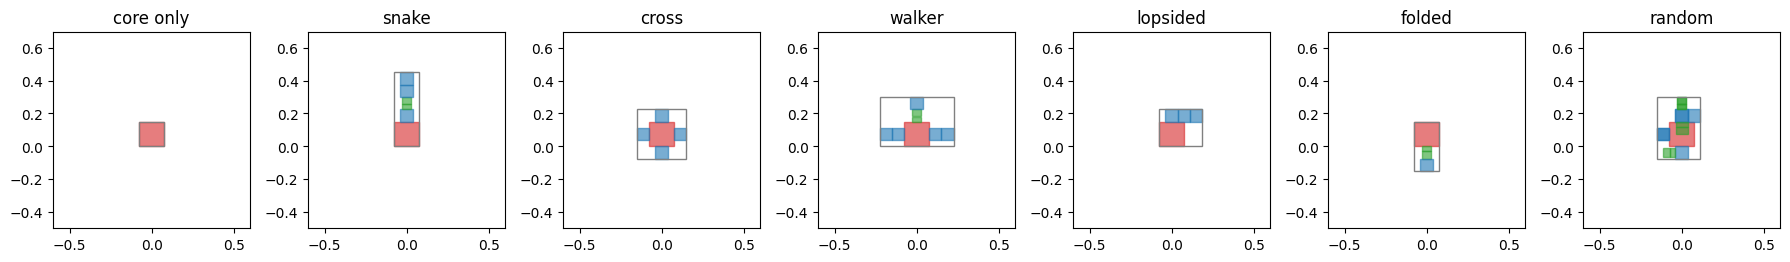

In [6]:
COLOURS = {"CORE": "tab:red", "BRICK": "tab:blue", "HINGE": "tab:green"}
fig, axes = plt.subplots(1, len(robots), figsize=(18, 3.2))
for axis, (name, robot) in zip(axes, robots.items(), strict=True):
    boxes = rest_boxes(robot)
    centres = boxes.poses[:, :3, 3]
    reach = np.einsum(
        "nij,nj->ni", np.abs(boxes.poses[:, :3, :3]), boxes.halves
    )
    graph = robot.graph
    assert graph is not None
    for owner, centre, half in zip(boxes.owners, centres, reach, strict=True):
        kind = graph.nodes[owner]["type"]
        axis.add_patch(
            Rectangle(
                (centre[0] - half[0], centre[1] - half[1]),
                2 * half[0],
                2 * half[1],
                color=COLOURS[kind],
                alpha=0.6,
            )
        )
    low = (centres - reach).min(axis=0)
    high = (centres + reach).max(axis=0)
    axis.add_patch(
        Rectangle(
            (low[0], low[1]),
            high[0] - low[0],
            high[1] - low[1],
            fill=False,
            edgecolor="grey",
        )
    )
    axis.set_xlim(-0.6, 0.6)
    axis.set_ylim(-0.5, 0.7)
    axis.set_aspect("equal")
    axis.set_title(name)
plt.tight_layout()
plt.show()

## The measures side by side

The proportions are between 0 and 1; depth and width are in metres. Read the table against the pictures: the snake has one long limb and no symmetry, the cross is symmetric, the walker is the only one with a joint besides the snake and the folded limb, and the folded limb is as long as its three modules.

In [7]:
table = Table(title="Morphological measures")
table.add_column("body")
table.add_column("depth m", justify="right")
table.add_column("width m", justify="right")
for measure in MEASURES:
    table.add_column(
        measure.replace("_", " "), justify="right", overflow="fold"
    )
for name, result in measures.items():
    table.add_row(
        name,
        f"{result.bounding_box_depth:.3f}",
        f"{result.bounding_box_width:.3f}",
        *(f"{getattr(result, m):.2f}" for m in MEASURES),
    )
console.print(table)

                                              Morphological measures                                               
┏━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┓
┃          ┃         ┃         ┃          ┃       ┃          ┃          ┃          ┃          ┃        ┃   module ┃
┃          ┃         ┃         ┃ branchin ┃       ┃   length ┃          ┃ proporti ┃          ┃        ┃ diversit ┃
┃ body     ┃ depth m ┃ width m ┃        g ┃ limbs ┃ of limbs ┃ coverage ┃       on ┃ symmetry ┃ joints ┃        y ┃
┡━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━┩
│ core     │   0.150 │   0.150 │     0.00 │  0.00 │     0.00 │     1.00 │     1.00 │     0.00 │   0.00 │     0.00 │
│ only     │         │         │          │       │          │          │          │          │        │          │
│ snake    │   0.450 │   0.150 │     0.00 │  0.25 │     1.00 │     0.48 │     0.33 │     0.00 │   0.25 │     0.67 │
│ cross    │   0.300 │   0.300 │     0.00 │  1.00 │     0.00 │     0.38 │     1.00 │     1.00 │   0.00 │     0.00 │
│ walker   │   0.300 │   0.450 │     0.00 │  0.60 │     0.60 │     0.28 │     0.67 │     1.00 │   0.17 │     0.33 │
│ lopsided │   0.225 │   0.263 │     0.00 │  0.33 │     1.00 │     0.52 │     0.86 │     0.00 │   0.00 │     0.00 │
│ folded   │   0.300 │   0.150 │     0.00 │  0.50 │     1.00 │     0.59 │     0.50 │     0.00 │   0.50 │     1.00 │
│ random   │   0.375 │   0.263 │     0.00 │  0.75 │     0.22 │     0.30 │     0.70 │     0.25 │   0.40 │     0.57 │
└──────────┴─────────┴─────────┴──────────┴───────┴──────────┴──────────┴──────────┴──────────┴────────┴──────────┘

In [8]:
for result in measures.values():
    for measure in MEASURES:
        assert 0.0 <= getattr(result, measure) <= 1.0
assert measures["core only"].limbs == 0
assert measures["core only"].symmetry == 0
assert math.isclose(measures["core only"].bounding_box_depth, CORE_SIDE)
assert math.isclose(measures["cross"].symmetry, 1.0)
assert measures["snake"].symmetry == 0
assert math.isclose(measures["snake"].length_of_limbs, 1.0)
assert measures["walker"].joints > measures["cross"].joints
assert measures["walker"].symmetry > measures["lopsided"].symmetry
assert measures["folded"].num_modules == FOLDED_MODULES
assert measures["folded"].bounding_box_depth > CORE_SIDE + 0.1

## Bad input is an error you can read

A robot whose graph has an edge without a valid face cannot be measured, so the measures refuse it and name the edge. A core made by hand, with no builder, has no graph at all and is refused too.

In [9]:
robot = construct_mjspec_from_graph(bodies["cross"].to_networkx())
assert robot.graph is not None
robot.graph.edges[0, 1]["face"] = "UP"
try:
    MorphologicalMeasures(robot)
except ValueError as error:
    message = str(error)
console.print(message)
assert "0 -> 1" in message

Edge 0 -> 1 has no valid face ('UP'); valid faces are FRONT, BACK, RIGHT, LEFT, TOP, BOTTOM